# Frente 3 — Carreira: trajetória e objetivos

**PRO3201 — Estatística e Aplicações · Grupo 10 (J)**

**Pergunta da frente:** como a vivência no grupo de extensão se conecta ao horizonte profissional de curto prazo (estágio e objetivo atual) e de médio prazo (área pretendida após a formatura)?

### Como ler este notebook

- **Leia como um artigo.** As células de código só chamam funções com nomes autoexplicativos (em inglês, pela convenção do README). A lógica fica em `src/`:
  - `stats_tests.py`: testes da disciplina;
  - `regression.py`: regressão linear múltipla;
  - `carreira.py`: preparação dos dados e agrupamentos;
  - `plotting/plots_carreira.py`: gráficos.
- **Cada pergunta segue os itens (a) a (e) do guia:** hipóteses; teste e premissas; resultado; gráfico ou tabela; conclusão para o relatório.
- **Métodos:** só os da disciplina (qui-quadrado, ANOVA com Bartlett e Scheffé, regressão linear com F parcial), α = 5%.
- **Perguntas do guia cortadas:**
  - P5 (o estágio derruba as horas no grupo): praticamente ninguém da amostra está estagiando;
  - P8 (prever a área pretendida): com 6 áreas, n = 187 e sem regressão logística, a previsão não se sustenta.

## 0. Preparação

*Célula técnica: só carrega as funções e os dados. Pode ser pulada na leitura.*

In [1]:
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path

ROOT_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_DIR, FIG_DIR, TAB_DIR = ROOT_DIR / "data", ROOT_DIR / "output" / "figures", ROOT_DIR / "output" / "tables"
FIG_DIR.mkdir(parents=True, exist_ok=True)
TAB_DIR.mkdir(parents=True, exist_ok=True)
if str(ROOT_DIR) not in sys.path:
    sys.path.append(str(ROOT_DIR))

import pandas as pd

from src.carreira import (AREA_ORDER, CAREER_CONTRASTS, CAREER_GROUP_ORDER, CAREER_ORDER, MAIN_VARIABLES,
                          REGRESSION_BLOCKS, REGRESSION_COLUMNS, REGRESSION_LABELS, YEAR_GROUP_ORDER, analysis_sample,
                          build_scenarios, category_distribution, grouping_table, prepare_front_data)
from src.plotting.plots_carreira import (plot_category_distribution, plot_means_panels, plot_residual_diagnostics,
                                         plot_scenario_probabilities, plot_stacked_shares)
from src.regression import (backward_elimination, coefficient_table, fit_ols, joint_partial_f_test, model_summary,
                            predict_scenarios)
from src.stats_tests import (chi_square_association, group_means, one_way_anova, row_percentages, scheffe_contrasts,
                             standardized_residuals)

pd.set_option("display.max_columns", None)
df = prepare_front_data(pd.read_parquet(DATA_DIR / "clean_data.parquet"))
print(f"{len(df)} alunos carregados.")

187 alunos carregados.


## 1. Dados e cuidados gerais

- **Base:** `clean_data.parquet` gerado de novo em 25/11, com 187 alunos da Poli, todos participantes de grupos de extensão. Na versão de 24/11, a coluna `anos_de_poli` estava desalinhada para 30 alunos. A preparação confere que ela bate com o ano de ingresso e interrompe a execução se receber um arquivo antigo.
- **A amostra é jovem:** 31 alunos no 1º ano, 93 no 2º e 63 no 3º ano ou depois (só 9 no 4º ou 5º). Por isso, **o momento do estágio mede intenção**, não um fato. A maioria ainda não chegou à idade de estagiar.
- **Agrupamentos (tabela abaixo):** o teste qui-quadrado só é confiável quando poucas caselas têm frequência esperada abaixo de 5. Usamos o mesmo critério da Frente 1: no máximo cerca de 20% das caselas. Cada agrupamento foi escolhido para cumprir esse critério, e o motivo aparece na tabela.
- **Exclusões feitas teste a teste, sem apagar linhas da base:**
  - "Outros" na motivação (n = 7) fica fora do qui-quadrado da P2;
  - "Indefinido" na área pretendida (n = 20) fica fora só da P1b;
  - as 7 respostas sem objetivo ficam fora dos testes que usam objetivo;
  - a única resposta "Não pretendo realizar estágio" fica fora da P3 e da P7.

> **Conceito — linguagem associativa.** Todos os alunos da amostra fazem extensão, e não há grupo de controle. Os testes mostram **associações** ("quem está no grupo X tende a mirar a área Y"), não efeitos causais ("o grupo X leva a mirar Y"). Também pode ser que o aluno escolha o grupo por já mirar a área.

In [2]:
groupings = grouping_table(df)
groupings.to_csv(TAB_DIR / "f3_tab02_agrupamentos.csv", index=False)
groupings

,Variável,Categorias originais,Nova categoria,n,Motivo
0,categoria_extensao,Consultoria & Negócios + Empreendedorismo,Consultoria & Negócios,108,Empreendedorismo tem n = 8; mesma decisão da F...
1,area_pretendida,Consultoria + Empreendedorismo,Consultoria & Empreendedorismo,52,"Com 6 áreas, 28% das caselas da P1a ficam com ..."
2,motivacao_ingresso,Networking e contato com empresas + Indicação ...,Outros,7,"n = 7; aparece na descritiva, mas fica fora do..."
3,objetivo_faculdade,Desempenho acadêmico + IC / Pesquisa,Desempenho & Pesquisa,33,"IC / Pesquisa tem n = 6; com 5 objetivos, 33% ..."
4,anos_de_poli,3 + 4 + 5,3º ano ou mais,63,Só 9 alunos estão no 4º ou 5º ano
5,momento_estagio,Antes do 3º ano + No 3ºano,Até o 3º ano,82,"Corte da P3 e da P7; mede intenção, pois a mai..."
6,momento_estagio,No 4ºano + A partir do 5ºano,4º ano ou depois,104,Idem
7,momento_estagio,Não pretendo realizar estágio,Excluído (sem valor),1,n = 1
8,media_ponderada,Menor que 5.0 + 5.0 a 5.9 + 6.0 a 6.9,"Abaixo de 7,0",71,Checagem ordinal da P6: as faixas das pontas t...
9,media_ponderada,8.0 a 8.9 + 9.0 a 10.0,"8,0 ou mais",41,Idem


## 2. Diagnóstico descritivo

A tabela descritiva é a `f3_tab01`, mesmo aparecendo depois da `f3_tab02`: a numeração segue a ordem de leitura do relatório, que começa pela descritiva. Os cuidados com os dados vêm antes, por isso a ordem das células.

In [3]:
descriptive = category_distribution(df, MAIN_VARIABLES)
descriptive.to_csv(TAB_DIR / "f3_tab01_descritiva.csv")
descriptive

n  \
Variável                              Categoria                                                 
Área pretendida após a formatura      Mercado Financeiro                                   49   
                                      Consultoria                                          33   
                                      Empreendedorismo                                     19   
                                      Indústria/Engenharia                                 42   
                                      Tecnologia                                           24   
                                      Indefinido                                           20   
Quando pretende fazer o 1º estágio    Até o 3º ano                                         82   
                                      4º ano ou depois                                    104   
                                      Sem resposta                                          1   
Objetivo principal atual na faculdade Desempenho acadêmico                                 27   
                                      Estágio                                              48   
                                      Grupo de extensão                                    77   
                                      IC / Pesquisa                                         6   
                                      Intercâmbio                                          22   
                                      Sem resposta                                          7   
Motivação para entrar no grupo        Adquirir experiência prática em projetos reais       46   
                                      Aprendizado técnico (hardskills)                     47   
                                      Desenvolvimento pessoal, comunicação e lideranç...   40   
                                      Interesse pela temática e objetivos do grupo         47   
                                      Outros                                                7   
Categoria do grupo de extensão        Consultoria & Negócios                              108   
                                      Engenharia                                           45   
                                      Mercado Financeiro                                   34   
Ano na Poli                           1º ano                                               31   
                                      2º ano                                               93   
                                      3º ano ou mais                                       63   

                                                                                             %  
Variável                              Categoria                                                 
Área pretendida após a formatura      Mercado Financeiro                                  26.2  
                                      Consultoria                                         17.6  
                                      Empreendedorismo                                    10.2  
                                      Indústria/Engenharia                                22.5  
                                      Tecnologia                                          12.8  
                                      Indefinido                                          10.7  
Quando pretende fazer o 1º estágio    Até o 3º ano                                        43.9  
                                      4º ano ou depois                                    55.6  
                                      Sem resposta                                         0.5  
Objetivo principal atual na faculdade Desempenho acadêmico                                14.4  
                                      Estágio                                             25.7  
                                      Grupo de extensão                                   41.2  
                 

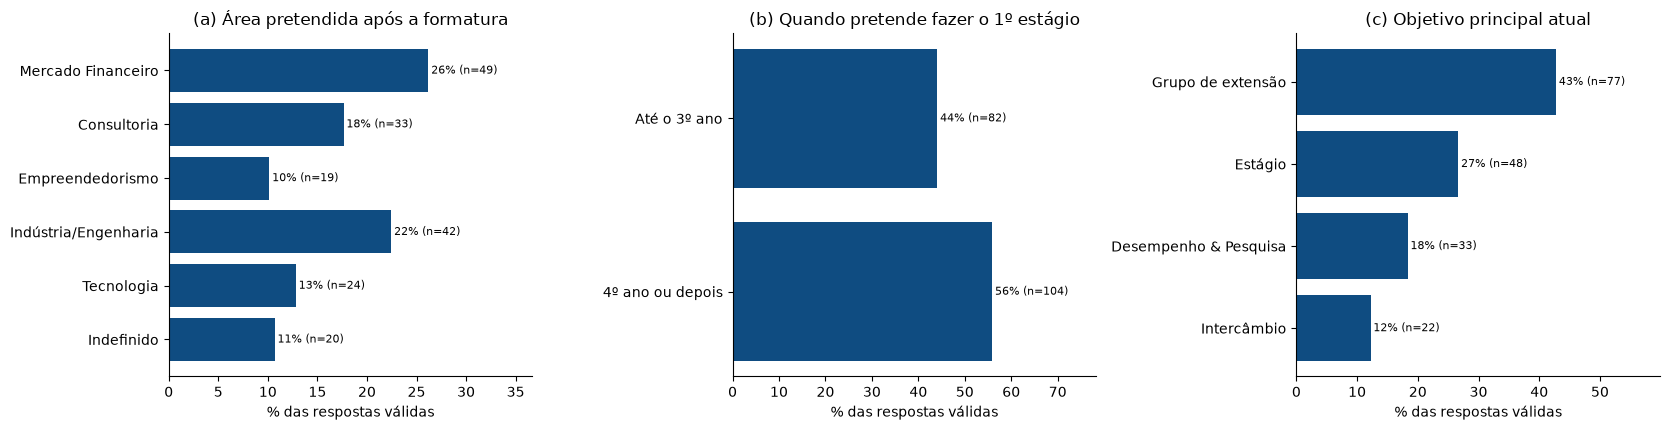

In [4]:
plot_category_distribution(df, [("area_pretendida", "(a) Área pretendida após a formatura"),
                                ("estagio_antecipado", "(b) Quando pretende fazer o 1º estágio"),
                                ("objetivo_grupo", "(c) Objetivo principal atual")],
                           FIG_DIR / "f3_fig01_distribuicao_variaveis_principais.png")

**Leitura.**

- **Área pretendida:** Mercado Financeiro é a mais citada (49 alunos; 26%), seguida de Indústria/Engenharia (42; 22%) e Consultoria (33; 18%). Só 20 alunos (11%) estão indefinidos.
- **Estágio:** 82 de 186 respondentes (44%) pretendem fazer o 1º estágio até o 3º ano e 104 (56%) só a partir do 4º. Como a amostra é jovem, isso é intenção, não fato.
- **Objetivo atual:** "Grupo de extensão" é o mais comum (77 de 180; 43%), à frente de Estágio (48; 27%). Intercâmbio tem 22 (12%) e Desempenho acadêmico e IC/Pesquisa juntos, 33 (18%).
- **Perfil da amostra:** 31 alunos no 1º ano (17%), 93 no 2º (50%) e 63 no 3º ano ou mais (34%); 108 (58%) estão em grupos de Consultoria & Negócios.

## 3. P1 — A área pretendida está associada ao grupo de extensão e ao curso?

**(a) Pergunta e hipóteses.** Dois testes de associação.

- **P1a** — área pretendida × categoria do grupo:
  - $H_0$: a área pretendida é independente da categoria do grupo;
  - $H_1$: há associação.
- **P1b** — área pretendida × grande área do curso:
  - $H_0$: a área pretendida é independente da grande área do curso;
  - $H_1$: há associação.

**(b) Teste e premissas.** Qui-quadrado de associação. As premissas são duas: observações independentes (um aluno por linha) e no máximo cerca de 20% das caselas com frequência esperada abaixo de 5.

- Na P1a, Consultoria e Empreendedorismo foram somadas como área pretendida (tabela de agrupamentos).
- Na P1b, os 20 alunos "Indefinido" ficam de fora. Com eles, 28% das caselas ficam abaixo de 5; sem eles, 10%.

> **Conceito — resíduo padronizado ajustado.** O qui-quadrado diz *se* há associação, mas não *onde*. Para cada casela, o resíduo ajustado compara o observado com o esperado sob independência, em unidades de desvio-padrão: $r = (O - E) / \sqrt{E (1 - p_{\text{linha}})(1 - p_{\text{coluna}})}$. Sob $H_0$, ele segue aproximadamente uma normal padrão. Por isso, $|r| > 2$ indica uma casela com bem mais (r positivo) ou bem menos (r negativo) alunos do que o esperado.
>
> **Conceito — V de Cramér.** $V = \sqrt{\chi^2 / (n \cdot k)}$, com $k$ = min(linhas, colunas) − 1. Vai de 0 (nenhuma associação) a 1 (associação total). As referências de Cohen dependem do $k$ de cada tabela: para $k = 2$, 0,07 fraca, 0,21 moderada e 0,35 forte; para $k = 3$, 0,06 fraca, 0,17 moderada e 0,29 forte.

In [5]:
p1a_sample = analysis_sample(df, ["area_grupo", "categoria_grupo"])
p1a_observed, p1a_result = chi_square_association(p1a_sample, "categoria_grupo", "area_grupo")
p1b_sample = analysis_sample(df, ["area_grupo", "grande_area_curso"], exclude={"area_grupo": ["Indefinido"]})
p1b_observed, p1b_result = chi_square_association(p1b_sample, "grande_area_curso", "area_grupo")

p1_results = pd.concat({"P1a: área pretendida × categoria do grupo": p1a_result.iloc[:, 0],
                        "P1b: área pretendida × grande área do curso (sem Indefinido)": p1b_result.iloc[:, 0]},
                       axis=1).T.rename_axis("Teste")
p1a_observed.to_csv(TAB_DIR / "f3_tab03_p1_area_x_categoria.csv")
p1b_observed.to_csv(TAB_DIR / "f3_tab04_p1_area_x_grande_area.csv")
p1_results.to_csv(TAB_DIR / "f3_tab05_p1_qui_quadrado.csv")
p1_results

,Qui-quadrado (χ²),Graus de liberdade,p-valor,"V de Cramér (0 = nenhuma, 1 = total)",Menor frequência esperada,% de caselas com esperado < 5,Decisão (α = 5%)
Teste,,,,,,,
P1a: área pretendida × categoria do grupo,95.02,8,4.4e-17,0.504,3.64,20%,Rejeita H0
P1b: área pretendida × grande área do curso (sem Indefinido),60.43,12,1.9e-08,0.347,3.02,10%,Rejeita H0


In [6]:
print("P1a — contagens e % por categoria do grupo")
display(p1a_observed)
display(row_percentages(p1a_observed))
print("P1a — resíduos padronizados ajustados (|r| > 2 em destaque na leitura)")
p1a_residuals = standardized_residuals(p1a_observed)
p1a_residuals.to_csv(TAB_DIR / "f3_tab06_p1a_residuos.csv")
p1a_residuals

P1a — contagens e % por categoria do grupo


area_grupo,Mercado Financeiro,Consultoria & Empreendedorismo,Indústria/Engenharia,Tecnologia,Indefinido
categoria_grupo,,,,,
Consultoria & Negócios,27,43,13,12,13
Engenharia,0,3,27,12,3
Mercado Financeiro,22,6,2,0,4


area_grupo,Mercado Financeiro,Consultoria & Empreendedorismo,Indústria/Engenharia,Tecnologia,Indefinido
categoria_grupo,,,,,
Consultoria & Negócios,25.0,39.8,12.0,11.1,12.0
Engenharia,0.0,6.7,60.0,26.7,6.7
Mercado Financeiro,64.7,17.6,5.9,0.0,11.8


P1a — resíduos padronizados ajustados (|r| > 2 em destaque na leitura)


area_grupo,Mercado Financeiro,Consultoria & Empreendedorismo,Indústria/Engenharia,Tecnologia,Indefinido
categoria_grupo,,,,,
Consultoria & Negócios,-0.44,4.28,-3.99,-0.82,0.69
Engenharia,-4.59,-3.63,6.92,3.18,-1.00
Mercado Financeiro,5.64,-1.46,-2.56,-2.47,0.22


In [7]:
print("P1b — contagens e % por grande área do curso")
display(p1b_observed)
display(row_percentages(p1b_observed))
p1b_residuals = standardized_residuals(p1b_observed)
p1b_residuals.to_csv(TAB_DIR / "f3_tab07_p1b_residuos.csv")
p1b_residuals

P1b — contagens e % por grande área do curso


area_grupo,Mercado Financeiro,Consultoria & Empreendedorismo,Indústria/Engenharia,Tecnologia
grande_area_curso,,,,
Civil & Ambiental,12,15,12,1
Elétrica & Computação,11,10,6,15
"Mecânica, Mecatrônica & Naval",6,6,22,5
Produção,13,10,0,2
Outras Engenharias,7,11,2,1


area_grupo,Mercado Financeiro,Consultoria & Empreendedorismo,Indústria/Engenharia,Tecnologia
grande_area_curso,,,,
Civil & Ambiental,30.0,37.5,30.0,2.5
Elétrica & Computação,26.2,23.8,14.3,35.7
"Mecânica, Mecatrônica & Naval",15.4,15.4,56.4,12.8
Produção,52.0,40.0,0.0,8.0
Outras Engenharias,33.3,52.4,9.5,4.8


area_grupo,Mercado Financeiro,Consultoria & Empreendedorismo,Indústria/Engenharia,Tecnologia
grande_area_curso,,,,
Civil & Ambiental,0.10,1.00,0.81,-2.45
Elétrica & Computação,-0.52,-1.19,-1.88,4.56
"Mecânica, Mecatrônica & Naval",-2.19,-2.43,5.14,-0.32
Produção,2.70,1.04,-3.14,-0.98
Outras Engenharias,0.43,2.25,-1.77,-1.34


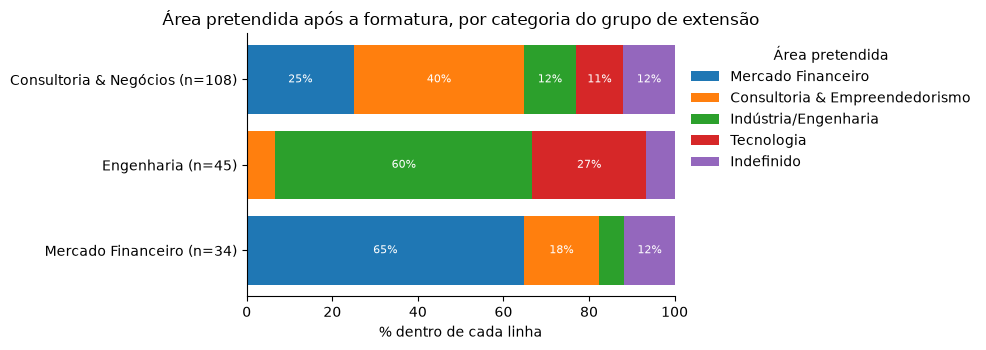

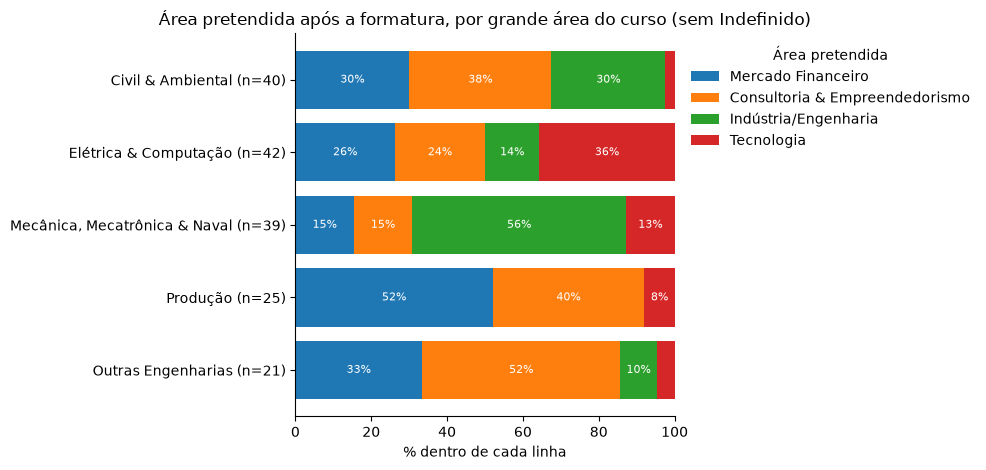

In [8]:
plot_stacked_shares(p1a_observed, "Área pretendida após a formatura, por categoria do grupo de extensão",
                    "Área pretendida", FIG_DIR / "f3_fig02_p1_area_por_categoria.png")
plot_stacked_shares(p1b_observed, "Área pretendida após a formatura, por grande área do curso (sem Indefinido)",
                    "Área pretendida", FIG_DIR / "f3_fig03_p1_area_por_grande_area.png")

**(c) Resultado.**

1. **P1a, área pretendida × categoria do grupo (n = 187):** χ²(8) = 95,0, p < 0,001, V de Cramér = 0,50, acima da referência de associação forte (0,35 para $k = 2$, tabela 3×5). A condição do teste é atendida no limite (20% das caselas com esperado abaixo de 5; menor esperado = 3,6). Caselas com |r| > 2:
   - **Mercado Financeiro:** 64,7% dos alunos desses grupos miram Mercado Financeiro (r = 5,64). Miram menos Indústria/Engenharia (5,9%; r = −2,56) e Tecnologia (0,0%; r = −2,47).
   - **Consultoria & Negócios:** 39,8% miram Consultoria & Empreendedorismo (r = 4,28) e só 12,0% miram Indústria/Engenharia (r = −3,99).
   - **Engenharia:** 60,0% miram Indústria/Engenharia (r = 6,92) e 26,7% miram Tecnologia (r = 3,18). Miram menos Mercado Financeiro (0,0%; r = −4,59) e Consultoria & Empreendedorismo (6,7%; r = −3,63).
2. **P1b, área pretendida × grande área do curso, sem Indefinido (n = 167):** χ²(12) = 60,4, p < 0,001, V de Cramér = 0,35, acima da referência de associação forte (0,29 para $k = 3$, tabela 5×4). A condição do teste é atendida (10% das caselas com esperado abaixo de 5; menor esperado = 3,0). Caselas com |r| > 2:
   - **Mecânica, Mecatrônica & Naval:** 56,4% miram Indústria/Engenharia (r = 5,14). Miram menos Mercado Financeiro (15,4%; r = −2,19) e Consultoria & Empreendedorismo (15,4%; r = −2,43).
   - **Elétrica & Computação:** 35,7% miram Tecnologia (r = 4,56).
   - **Produção:** 52,0% miram Mercado Financeiro (r = 2,70) e nenhum aluno mira Indústria/Engenharia (0,0%; r = −3,14).
   - **Civil & Ambiental:** só 2,5% miram Tecnologia (r = −2,45).
   - **Outras Engenharias:** 52,4% miram Consultoria & Empreendedorismo (r = 2,25).

**(d)** Figuras `f3_fig02` e `f3_fig03`, tabelas `f3_tab03` a `f3_tab07`.

**(e) Conclusão para o relatório.** A área pretendida está fortemente associada tanto à categoria do grupo (χ², p < 0,001; V = 0,50) quanto à grande área do curso (χ², p < 0,001; V = 0,35). Alunos de grupos de Mercado Financeiro tendem a mirar Mercado Financeiro (65%), os de Consultoria & Negócios miram Consultoria & Empreendedorismo (40%) e os de Engenharia miram Indústria/Engenharia (60%). Entre os cursos, destacam-se Mecânica (Indústria/Engenharia) e Elétrica & Computação (Tecnologia). Há possível autosseleção: o aluno pode ter escolhido o grupo pela área que já mirava, de modo que a associação não mostra que o grupo molda a área pretendida.

## 4. P2 — A motivação para entrar no grupo se reflete na área pretendida?

**(a) Pergunta e hipóteses.**

- $H_0$: a área pretendida é independente da motivação de ingresso;
- $H_1$: há associação.

**(b) Teste e premissas.** Qui-quadrado de associação, com resíduos ajustados.

- "Outros" (Networking, 6, e Indicação de amigos, 1) fica fora do teste: com essa linha, 40% das caselas ficam abaixo de 5; sem ela, 20%. Por isso n = 180.
- Consultoria e Empreendedorismo continuam somadas, como na P1.

In [9]:
p2_sample = analysis_sample(df, ["motivacao_grupo", "area_grupo"], exclude={"motivacao_grupo": ["Outros"]})
p2_observed, p2_result = chi_square_association(p2_sample, "motivacao_grupo", "area_grupo")
p2_observed.to_csv(TAB_DIR / "f3_tab08_p2_motivacao_x_area.csv")
p2_result.to_csv(TAB_DIR / "f3_tab09_p2_qui_quadrado.csv")
display(p2_observed)
display(row_percentages(p2_observed))
p2_result

area_grupo,Mercado Financeiro,Consultoria & Empreendedorismo,Indústria/Engenharia,Tecnologia,Indefinido
motivacao_grupo,,,,,
Adquirir experiência prática em projetos reais,6,11,14,7,8
Aprendizado técnico (hardskills),20,9,10,5,3
"Desenvolvimento pessoal, comunicação e liderança (softskills)",5,15,8,6,6
Interesse pela temática e objetivos do grupo,16,14,10,5,2


area_grupo,Mercado Financeiro,Consultoria & Empreendedorismo,Indústria/Engenharia,Tecnologia,Indefinido
motivacao_grupo,,,,,
Adquirir experiência prática em projetos reais,13.0,23.9,30.4,15.2,17.4
Aprendizado técnico (hardskills),42.6,19.1,21.3,10.6,6.4
"Desenvolvimento pessoal, comunicação e liderança (softskills)",12.5,37.5,20.0,15.0,15.0
Interesse pela temática e objetivos do grupo,34.0,29.8,21.3,10.6,4.3


,Teste de associação
Qui-quadrado (χ²),22.21
Graus de liberdade,12
p-valor,0.0352
"V de Cramér (0 = nenhuma, 1 = total)",0.203
Menor frequência esperada,4.22
% de caselas com esperado < 5,20%
Decisão (α = 5%),Rejeita H0


area_grupo,Mercado Financeiro,Consultoria & Empreendedorismo,Indústria/Engenharia,Tecnologia,Indefinido
motivacao_grupo,,,,,
Adquirir experiência prática em projetos reais,-2.34,-0.58,1.32,0.57,1.75
Aprendizado técnico (hardskills),2.99,-1.45,-0.39,-0.51,-1.08
"Desenvolvimento pessoal, comunicação e liderança (softskills)",-2.22,1.66,-0.57,0.48,1.04
Interesse pela temática e objetivos do grupo,1.44,0.46,-0.39,-0.51,-1.64


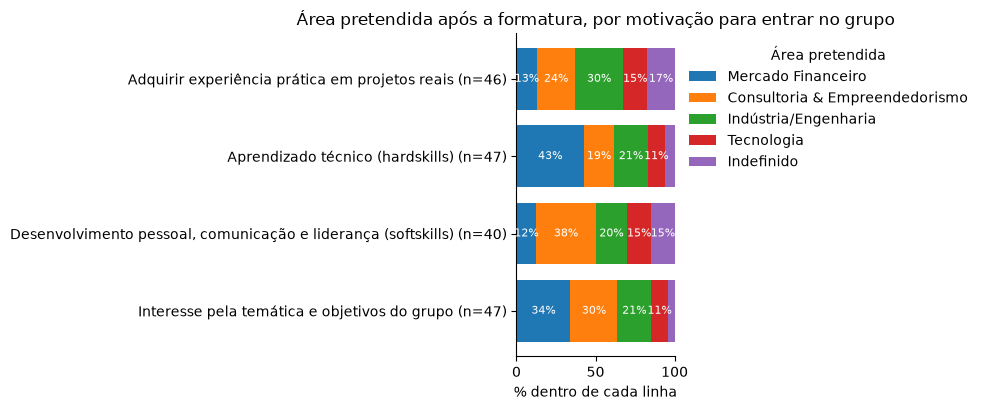

In [10]:
p2_residuals = standardized_residuals(p2_observed)
p2_residuals.to_csv(TAB_DIR / "f3_tab10_p2_residuos.csv")
display(p2_residuals)
plot_stacked_shares(p2_observed, "Área pretendida após a formatura, por motivação para entrar no grupo",
                    "Área pretendida", FIG_DIR / "f3_fig04_p2_area_por_motivacao.png")

**(c) Resultado.**

- **Teste (n = 180):** χ²(12) = 22,2, p = 0,035, V de Cramér = 0,20, acima da referência de associação moderada (0,17 para $k = 3$, tabela 4×5) e abaixo da forte (0,29). Rejeita-se $H_0$ ao nível de 5%. A condição do teste é atendida no limite (20% das caselas com esperado abaixo de 5; menor esperado = 4,2).
- **Caselas com |r| > 2:**
  - **Aprendizado técnico (hardskills):** 42,6% miram Mercado Financeiro (r = 2,99);
  - **Adquirir experiência prática em projetos reais:** só 13,0% miram Mercado Financeiro (r = −2,34);
  - **Desenvolvimento pessoal, comunicação e liderança:** só 12,5% miram Mercado Financeiro (r = −2,22).
- Nas demais caselas, os resíduos ficam dentro de ±2.

**(d)** Figura `f3_fig04`, tabelas `f3_tab08` a `f3_tab10`.

**(e) Conclusão para o relatório.** Há associação estatisticamente significativa entre a motivação de ingresso e a área pretendida (χ², p = 0,035), com associação moderada (V = 0,20; mais perto da referência moderada, 0,17, que da forte, 0,29), de magnitude modesta, e o p-valor fica perto do limite de 5%, então o resultado deve ser lido com cautela. A diferença concentra-se em Mercado Financeiro: quem entrou por aprendizado técnico mira essa área com mais frequência (43%) do que quem entrou por experiência prática (13%) ou por desenvolvimento pessoal (13%). Nas outras áreas, não há desvio claro em relação à independência.